# INF-8239 · Ejercicio 05 · Motor recomendador reproducible

**Unidad 03 · Sistemas recomendadores (LAB08 + LAB09)**

| Elemento | Definición |
|---|---|
| Datos | MovieLens ml-latest-small (GroupLens, 2018), descargado desde la fuente oficial; no se redistribuye |
| Tarea | Recomendar 10 películas no vistas a cada usuario |
| Relevante | Película valorada con 4 o más en el periodo evaluado |
| Partición | Corte temporal global (cuantil 0.80 de las fechas); validación con un segundo corte dentro de entrenamiento |
| Métricas | NDCG@10 (principal), precisión, recall, hit rate, cobertura, novedad, diversidad, RMSE |
| Modelos | Aleatorio, popularidad, contenido, factorización, híbrido LAB09, híbrido seleccionado y sistema con fallback |

> Recomendación offline: estima qué tan bien se habría anticipado el comportamiento pasado; no garantiza preferencias futuras.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
import runpy

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 90)
REPORTS = ROOT / "reports"
SCRIPTS = ROOT / "scripts"


def run(script, *args):
    sys.argv = [script, *args]
    try:
        runpy.run_path(str(SCRIPTS / script), run_name="__main__")
    except SystemExit as exit_:
        if exit_.code not in (0, None):
            raise


print("Raíz:", ROOT)

Raíz: /tmp/rec/INF8239_U03_E05_Recomendador


## 1. Datos y licencia
Se descarga el ZIP oficial de GroupLens y se registran sus hashes en `reports/data_manifest.json`. Los términos de uso de GroupLens prohíben redistribuir el dataset sin permiso, por eso `data/raw/` no se versiona.

In [2]:
run("download_data.py")
json.loads((REPORTS / "data_manifest.json").read_text())

MovieLens ya está en data/raw/ml-latest-small (no se descarga de nuevo)
Conteos: {'ratings': 100836, 'movies': 9742, 'users': 610} | coincide con la versión documentada: True
SHA-256 ZIP: None


{'source': 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip',
 'downloaded_or_checked_utc': '2026-10-07T19:04:52+00:00',
 'zip_sha256': None,
 'files_sha256': {'ratings.csv': '80da8b3393dae325bbba5a31f291a6ba55d8d4f4396de3c456f2c1635b1b70e8',
  'movies.csv': 'c47b783f23eb304413307e1bb05335e427737da20ec8d3c0e96335567dd5f3dc'},
 'counts': {'ratings': 100836, 'movies': 9742, 'users': 610},
 'matches_documented_version_2018_09_26': True}

## 2. Auditoría

Ratings: 100836 | Películas: 9742 | Usuarios: 610
Densidad: 0.0170 | Rango: 1996-03-29 18:36:55 a 2018-09-24 14:27:30
Por usuario: {'min': 20, 'median': 70.5, 'max': 2698} | Por película: {'median': 3.0, 'share_movies_with_1_rating': 0.3543809132044426, 'share_movies_with_lt5_ratings': 0.6246400658165364}
El 10 % de películas más valoradas concentra 60.0% de las valoraciones
Sin géneros: 34 | Sin año: 13 | Duplicados: 0 | Nulos: 0


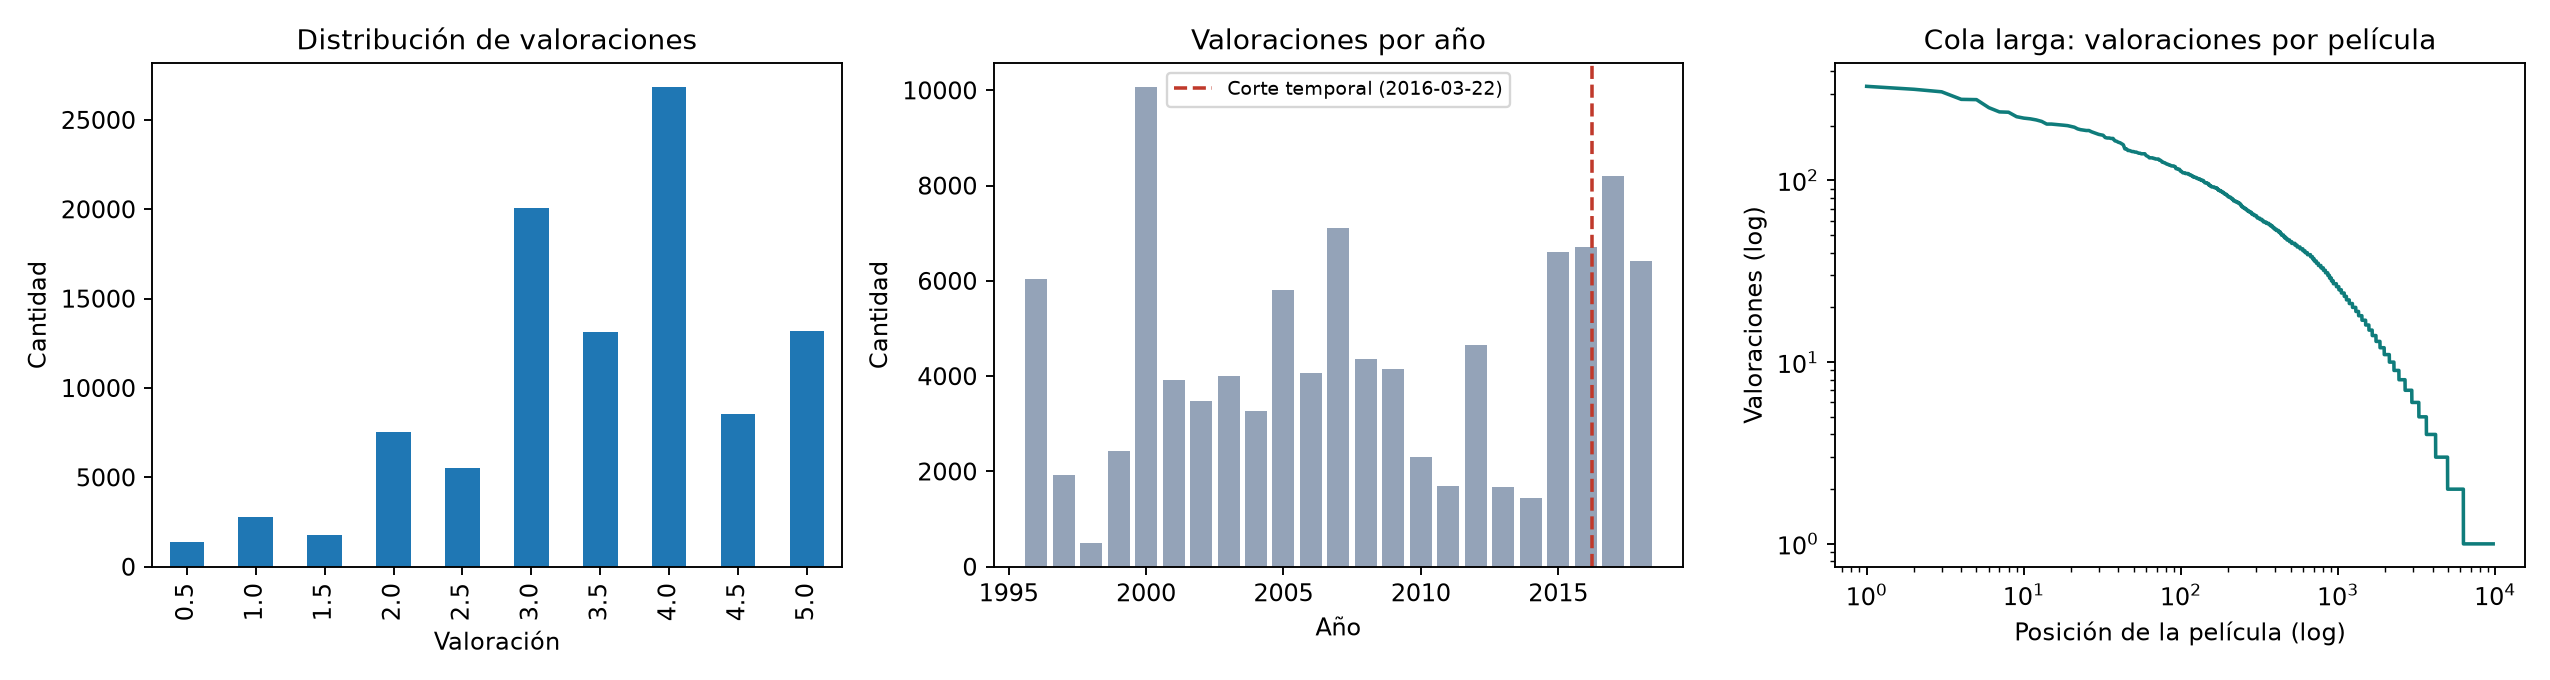

In [3]:
run("audit_data.py")
display(Image(REPORTS / "fig_audit.png", width=1000))

**Lectura.** Cada usuario tiene al menos 20 valoraciones, pero la matriz es muy dispersa (≈ 1.7 % de densidad) y la cola es larga: el 10 % de películas más valoradas concentra el 60 % de las valoraciones y el 35 % de las películas tiene una sola. Hay 34 películas sin géneros y 13 sin año, lo que limita el modelo de contenido. No hay duplicados ni nulos.

## 3. LAB08: popularidad ponderada y contenido ítem a ítem
*Exploración sobre todo el dataset; el experimento evaluado usa solo datos anteriores al corte.*

In [4]:
run("lab08_content.py")
display(pd.read_csv(REPORTS / "popular_top10.csv"))
display(pd.read_csv(REPORTS / "content_recommendations.csv"))

Popularidad:
                                                                                title  count      mean  weighted_score
movieId                                                                                                              
318                                                 Shawshank Redemption, The (1994)    317  4.429022        4.395194
858                                                            Godfather, The (1972)    192  4.289062        4.242739
2959                                                               Fight Club (1999)    218  4.272936        4.232690
260                                        Star Wars: Episode IV - A New Hope (1977)    251  4.231076        4.197790
50                                                        Usual Suspects, The (1995)    204  4.237745        4.196846
1221                                                  Godfather: Part II, The (1974)    129  4.259690        4.195168
527                                       

,movieId,title,count,mean,weighted_score
0,318,"Shawshank Redemption, The (1994)",317,4.429022,4.395194
1,858,"Godfather, The (1972)",192,4.289062,4.242739
2,2959,Fight Club (1999),218,4.272936,4.232690
3,260,Star Wars: Episode IV - A New Hope (1977),251,4.231076,4.197790
4,50,"Usual Suspects, The (1995)",204,4.237745,4.196846
5,1221,"Godfather: Part II, The (1974)",129,4.259690,4.195168
6,527,Schindler's List (1993),220,4.225000,4.187581
7,1213,Goodfellas (1990),126,4.250000,4.184918
8,750,Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964),97,4.268041,4.183658
9,58559,"Dark Knight, The (2008)",149,4.238255,4.183346


,movieId,title,genres,content_score
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.000000
1,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.000000
2,27186,Kirikou and the Sorceress (Kirikou et la sorcière) (1998),Adventure|Animation|Children|Fantasy,0.967379
3,3400,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.967379
4,2800,Little Nemo: Adventures in Slumberland (1992),Adventure|Animation|Children|Drama|Fantasy,0.940269
5,673,Space Jam (1996),Adventure|Animation|Children|Comedy|Fantasy|Sci-Fi,0.919493
6,558,"Pagemaster, The (1994)",Action|Adventure|Animation|Children|Fantasy,0.910656
7,91355,Asterix and the Vikings (Astérix et les Vikings) (2006),Adventure|Animation|Children|Comedy|Fantasy,0.905446
8,65577,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,0.905446
9,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,0.905446


## 4. Corte temporal, validación y experimento principal (LAB09)
*Tarda unos minutos: la factorización se entrena con SGD en Python.*

In [5]:
run("lab09_hybrid.py")
split = json.loads((REPORTS / "split_summary.json").read_text())
split

Corte: 2016-03-22 | cálidos: 28 | fríos: 88


Validación (124 tareas): factores = 20; lambda fold-in = 10.0; elegido = hibrido_p0.25_m0.50_c0.25


/tmp/rec/INF8239_U03_E05_Recomendador/scripts/lab09_hybrid.py:342: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(list(data.values()), vert=False, showfliers=False)


               model segment  users  ndcg@10  ndcg_ci95_low  ndcg_ci95_high  precision@10  recall@10  hit@10  coverage  novelty  diversity
           aleatorio   todos    204    0.018          0.011           0.025         0.019      0.001   0.132     0.036    7.481      0.861
           aleatorio  calido     28    0.010          0.000           0.021         0.011      0.003   0.107     0.035    7.269      0.824
           aleatorio frio_k0     88    0.019          0.008           0.031         0.020      0.001   0.136     0.001    7.515      0.867
           aleatorio frio_k5     88    0.019          0.008           0.031         0.020      0.001   0.136     0.001    7.515      0.867
         popularidad   todos    204    0.291          0.255           0.327         0.260      0.058   0.725     0.008    1.282      0.625
         popularidad  calido     28    0.086          0.021           0.164         0.075      0.039   0.250     0.008    1.549      0.645
         popularidad frio_k

{'cutoff_quantile': 0.8,
 'cutoff_timestamp': 1458635171,
 'cutoff_date': '2016-03-22',
 'train_ratings': 80668,
 'test_ratings': 20168,
 'train_users': 522,
 'test_users': 116,
 'warm_test_users': 28,
 'cold_test_users': 88,
 'catalog_size': 7867,
 'test_ratings_on_items_new_after_cutoff': 0.15093216977389926,
 'leave_one_out_test_events_with_later_training_data': 0.9983606557377049,
 'leave_one_out_train_ratings_after_median_test_time': 0.5043002813641171}

**Corte temporal.** El laboratorio original usaba *leave-one-out* por usuario: en esa partición, casi todos los eventos de prueba tienen valoraciones de otros usuarios posteriores en entrenamiento (`leave_one_out_test_events_with_later_training_data`), es decir, el modelo "ve el futuro". El corte global evita esa fuga. La mayoría de usuarios de prueba son nuevos (fríos), un rasgo real de MovieLens.

### 4.1 Validación: factores, fold-in y pesos del híbrido

,factors,fit_seconds,ndcg@10,ndcg_se,coverage
0,10,18.6942,0.1353,0.0139,0.0141
1,20,18.9168,0.1592,0.0153,0.0187
2,40,19.3040,0.1345,0.0135,0.0213


,fold_in_lambda,rmse_frio_k5
0,1.0,0.9659
1,5.0,0.9372
2,10.0,0.9333
3,25.0,0.9371
4,50.0,0.9417


,model,ndcg@10,ndcg_se,hit@10,coverage,novelty,is_pareto,selected
0,popularidad,0.2319,0.0205,0.6935,0.0100,1.2621,False,False
1,hibrido_p0.00_m0.00_c1.00,0.0227,0.0061,0.1371,0.1040,5.6772,True,False
2,hibrido_p0.00_m0.25_c0.75,0.0671,0.0098,0.3952,0.0934,5.0891,True,False
3,hibrido_p0.00_m0.50_c0.50,0.1180,0.0137,0.5484,0.0663,4.3146,True,False
4,hibrido_p0.00_m0.75_c0.25,0.1617,0.0161,0.6935,0.0312,3.8789,False,False
5,hibrido_p0.00_m1.00_c0.00,0.1408,0.0135,0.6452,0.0117,3.9553,False,False
6,hibrido_p0.25_m0.00_c0.75,0.1107,0.0147,0.4919,0.0725,2.9591,True,False
7,hibrido_p0.25_m0.25_c0.50,0.1908,0.0184,0.6935,0.0529,2.5344,True,False
8,hibrido_p0.25_m0.50_c0.25,0.2881,0.0234,0.7903,0.0248,2.0655,True,True
9,hibrido_p0.25_m0.75_c0.00,0.2731,0.0231,0.7419,0.0135,1.8360,False,False


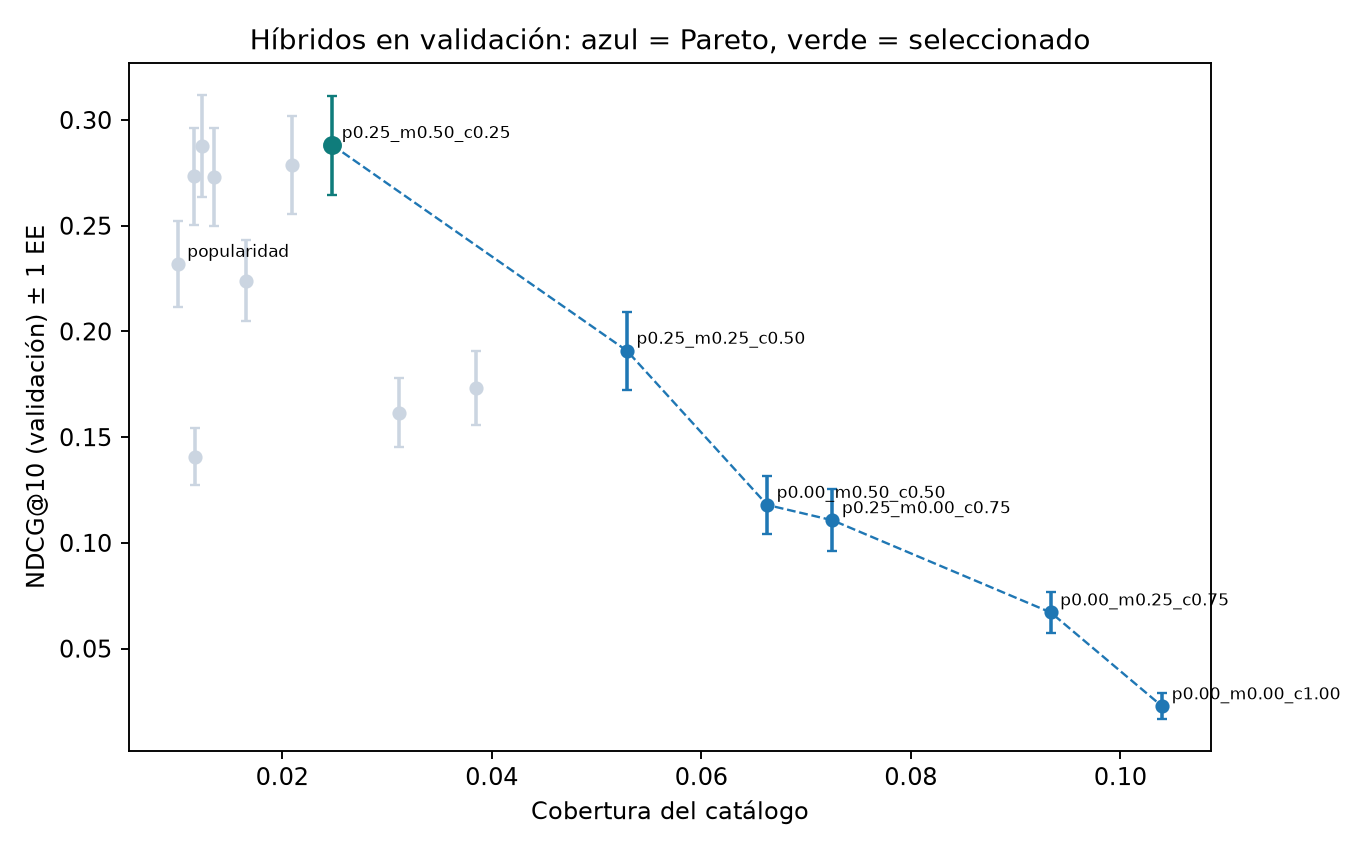

In [6]:
display(pd.read_csv(REPORTS / "validation_factors.csv").round(4))
display(pd.read_csv(REPORTS / "validation_fold_in.csv").round(4))
grid = pd.read_csv(REPORTS / "validation_grid.csv")
display(grid[["model", "ndcg@10", "ndcg_se", "hit@10", "coverage", "novelty", "is_pareto", "selected"]].round(4))
display(Image(REPORTS / "fig_pareto_validation.png", width=750))

### 4.2 Prueba (evaluación única)

Híbrido seleccionado: {'w_pop': 0.25, 'w_mf': 0.5, 'w_content': 0.25, 'name': 'hibrido_p0.25_m0.50_c0.25'}


,model,segment,users,ndcg@10,ndcg_ci95_low,...,hit@10,coverage,novelty,diversity,ms_per_user
0,aleatorio,todos,204,0.018,0.011,...,0.132,0.036,7.481,0.861,1.146
1,aleatorio,calido,28,0.010,0.000,...,0.107,0.035,7.269,0.824,1.146
2,aleatorio,frio_k0,88,0.019,0.008,...,0.136,0.001,7.515,0.867,1.146
3,aleatorio,frio_k5,88,0.019,0.008,...,0.136,0.001,7.515,0.867,1.146
4,popularidad,todos,204,0.291,0.255,...,0.725,0.008,1.282,0.625,0.892
5,popularidad,calido,28,0.086,0.021,...,0.250,0.008,1.549,0.645,0.892
6,popularidad,frio_k0,88,0.379,0.325,...,0.864,0.001,1.214,0.624,0.892
7,popularidad,frio_k5,88,0.269,0.215,...,0.739,0.002,1.264,0.620,0.892
8,contenido,todos,116,0.038,0.025,...,0.250,0.075,6.141,0.116,4.765
9,contenido,calido,28,0.019,0.003,...,0.143,0.025,6.794,0.162,4.765


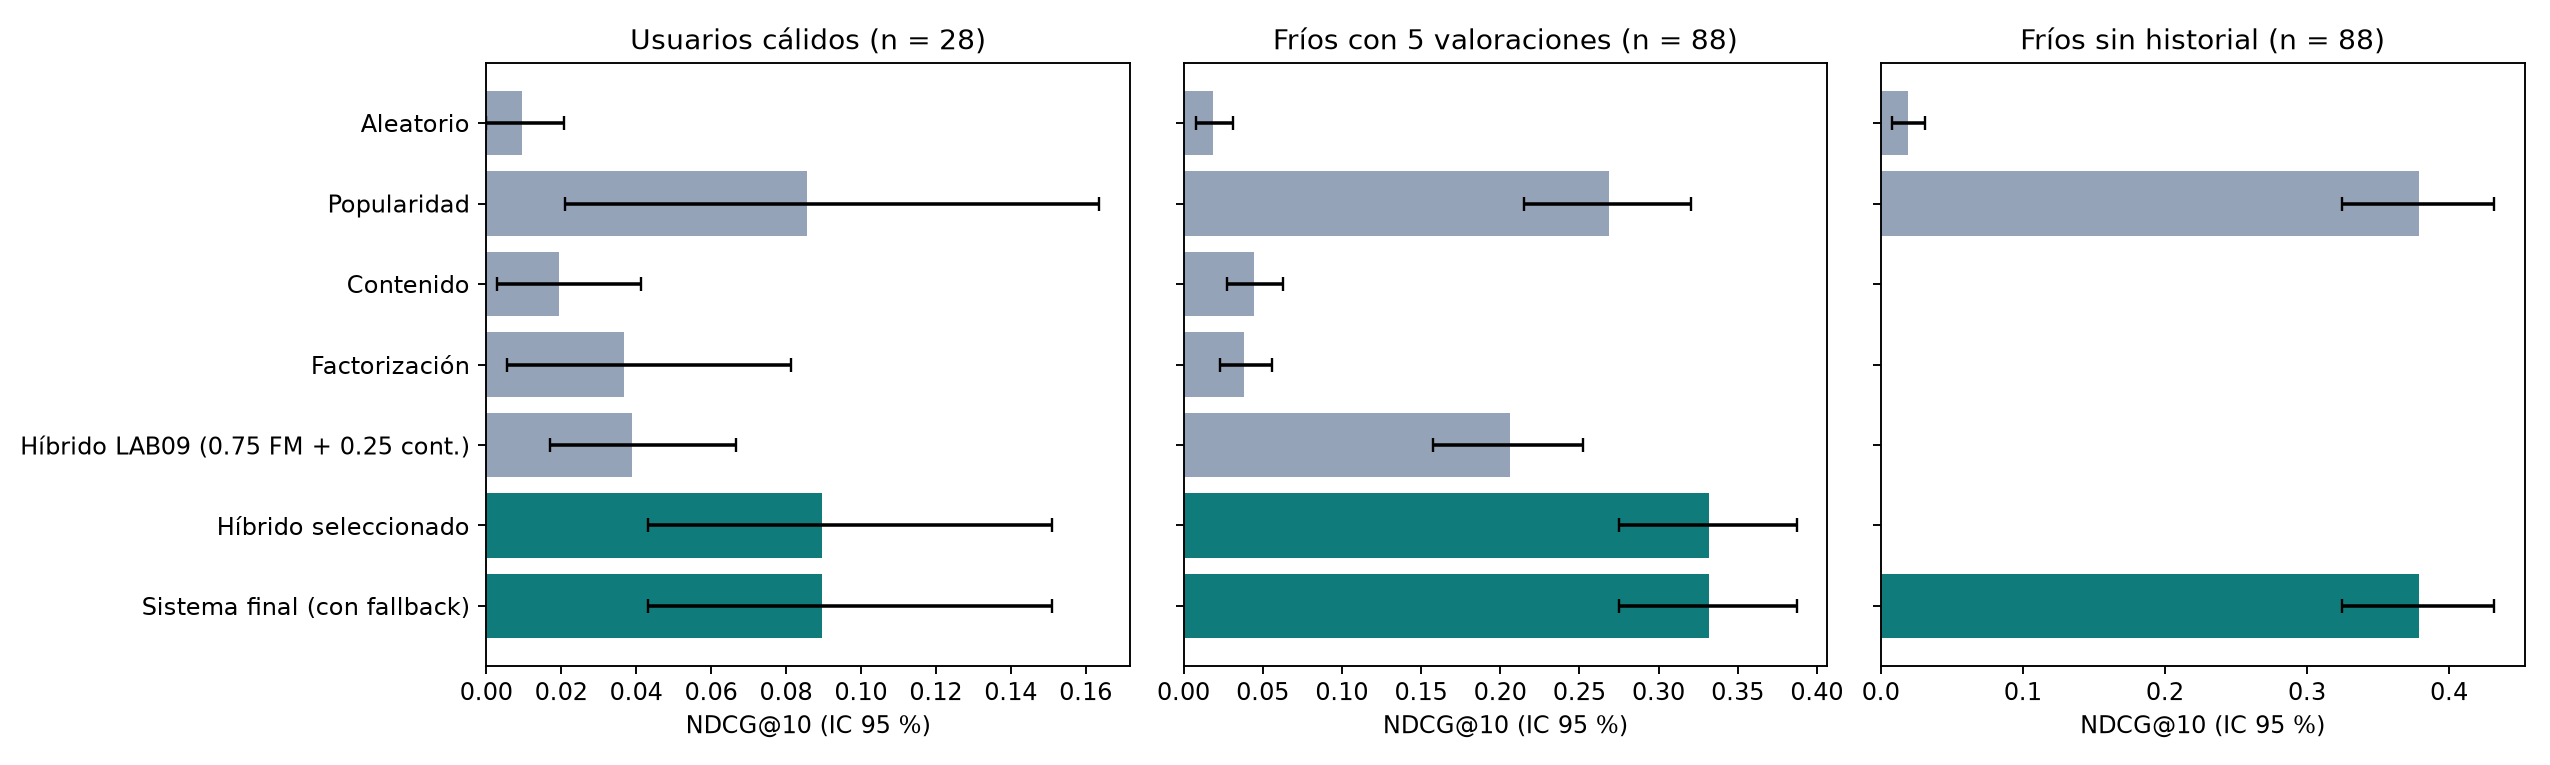

In [7]:
results = json.loads((REPORTS / "results.json").read_text())
print("Híbrido seleccionado:", results["selected_hybrid"])
table = pd.read_csv(REPORTS / "test_metrics.csv")
cols = ["model", "segment", "users", "ndcg@10", "ndcg_ci95_low", "ndcg_ci95_high", "precision@10",
        "recall@10", "hit@10", "coverage", "novelty", "diversity", "ms_per_user"]
display(table[cols].round(3))
display(Image(REPORTS / "fig_test_segments.png", width=1000))

In [8]:
display(pd.read_csv(REPORTS / "rmse.csv").round(4))

,segment,model,ratings,rmse
0,calido,media global,1311,1.1222
1,calido,media de la película,1311,1.0593
2,calido,factorización,1311,0.9221
3,frio_k5,media global,15400,1.0549
4,frio_k5,media de la película,15400,1.0227
5,frio_k5,factorización,15400,1.0079


## 5. Errores, sesgo de popularidad y usuarios fríos

,bucket,popularidad,sistema
0,0,0.379,0.379
1,1-5,0.269,0.332
2,6-50,0.182,0.151
3,51-200,0.055,0.028
4,>200,0.000,0.049


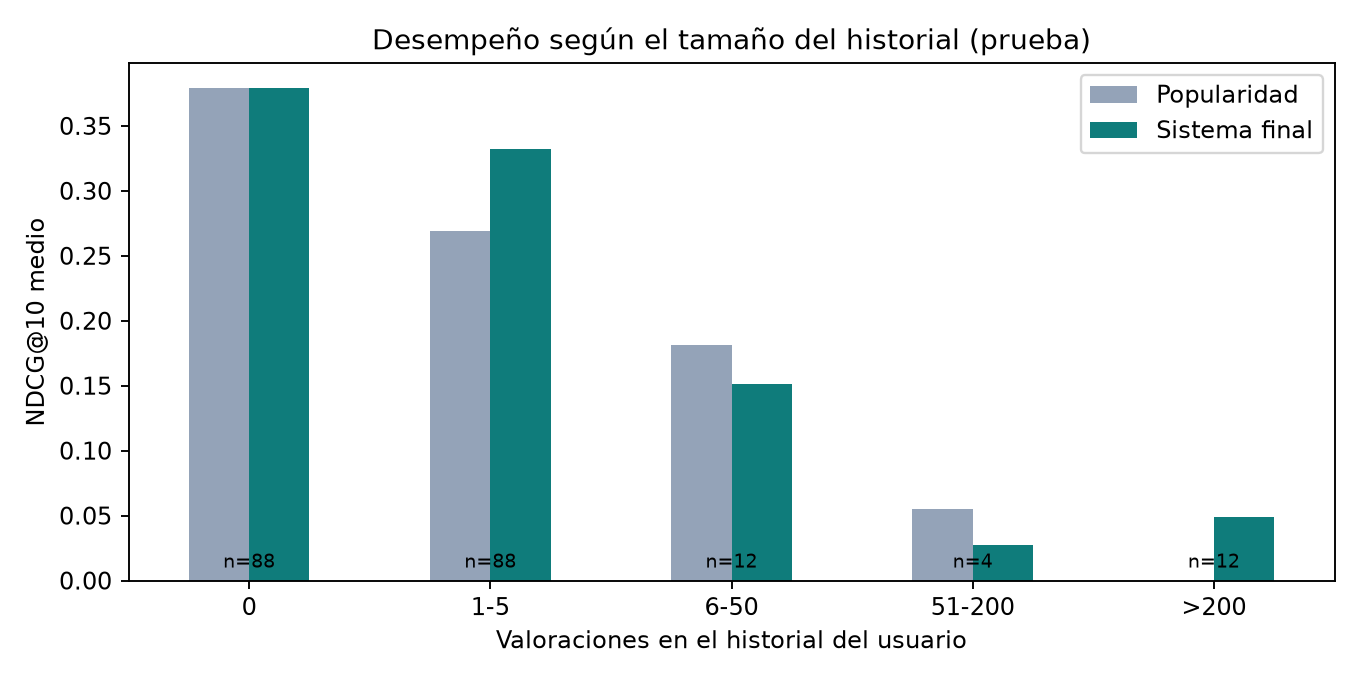

,Unnamed: 0,count,mean,std,min,50%,max,share_top100
0,Relevantes (verdad),7719.0,1304.019,1688.675,1.0,636.0,7865.0,0.164
1,Popularidad,1160.0,10.845,21.277,1.0,7.0,244.0,0.987
2,Factorización,1160.0,989.484,599.626,3.0,1079.0,3605.0,0.072
3,Contenido,1160.0,2909.675,2287.687,1.0,2384.0,7843.0,0.047
4,Híbrido seleccionado,1160.0,134.422,232.130,1.0,61.5,1912.0,0.705


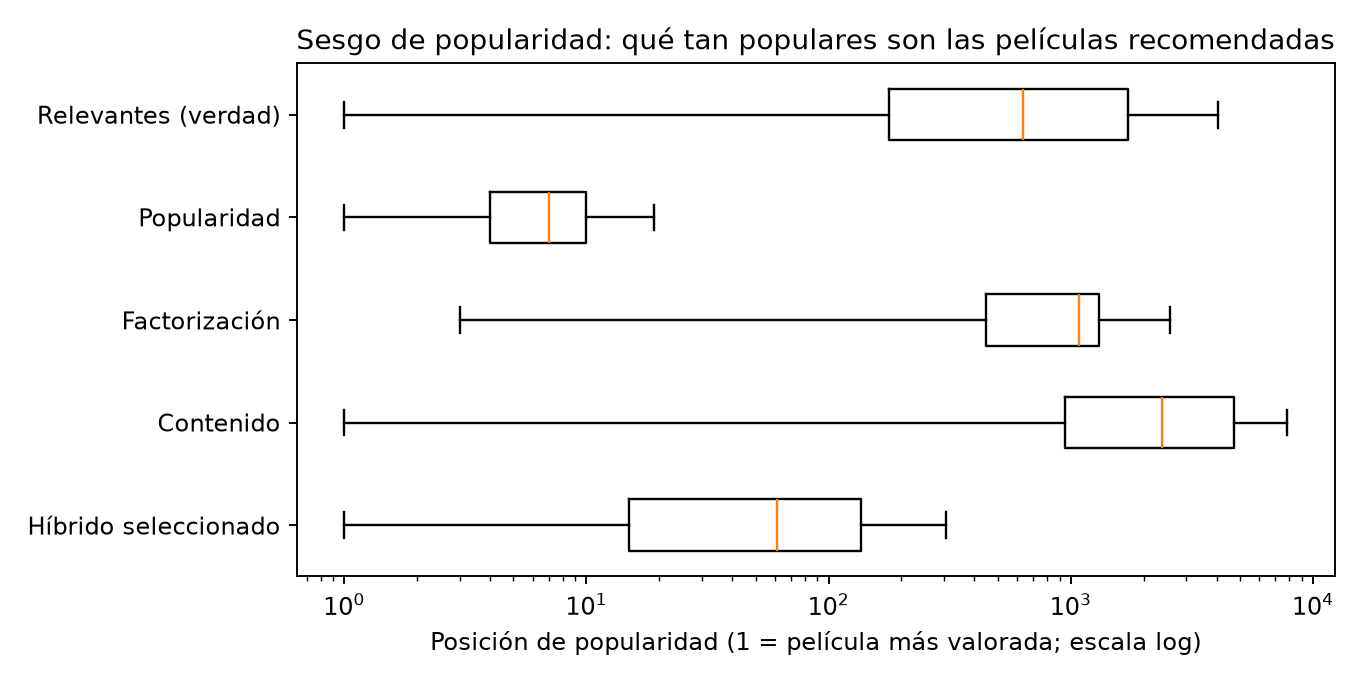

In [9]:
display(pd.read_csv(REPORTS / "ndcg_by_history_size.csv").round(3))
display(Image(REPORTS / "fig_history_size.png", width=700))
display(pd.read_csv(REPORTS / "popularity_bias.csv").round(3))
display(Image(REPORTS / "fig_popularity_bias.png", width=750))

In [10]:
display(pd.read_csv(REPORTS / "cold_start_fallback.csv"))
display(pd.read_csv(REPORTS / "example_recommendations.csv"))

,movieId,title,genres
0,356,Forrest Gump (1994),Comedy|Drama|Romance|War
1,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
2,318,"Shawshank Redemption, The (1994)",Crime|Drama
3,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
4,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller
5,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
6,110,Braveheart (1995),Action|Drama|War
7,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
8,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi
9,527,Schindler's List (1993),Drama|War


,userId,model,historial_favorito,recomendaciones,aciertos
0,15,popularidad,"Gods Must Be Crazy, The (1980) | Frequency (2000) | Lethal Weapon 2 (1989)","Forrest Gump (1994) | Pulp Fiction (1994) | Shawshank Redemption, The (1994) | Silence...","Forrest Gump (1994) | Pulp Fiction (1994) | Shawshank Redemption, The (1994) | Matrix,..."
1,15,hibrido_seleccionado,"Gods Must Be Crazy, The (1980) | Frequency (2000) | Lethal Weapon 2 (1989)","Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001) | Pulp Fiction (1994) | Raiders o...",Pulp Fiction (1994) | Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lo...
2,18,popularidad,"Citizen Kane (1941) | Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, I...","Apollo 13 (1995) | American Beauty (1999) | Batman (1989) | Fugitive, The (1993) | Sta...",NaN
3,18,hibrido_seleccionado,"Citizen Kane (1941) | Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, I...","City of God (Cidade de Deus) (2002) | Children of Men (2006) | Princess Bride, The (19...",Heat (1995)
4,21,popularidad,GoldenEye (1995) | Back to the Future Part III (1990) | Tomorrow Never Dies (1997),"Pulp Fiction (1994) | Shawshank Redemption, The (1994) | Silence of the Lambs, The (19...",NaN
5,21,hibrido_seleccionado,GoldenEye (1995) | Back to the Future Part III (1990) | Tomorrow Never Dies (1997),"Princess Bride, The (1987) | City of God (Cidade de Deus) (2002) | True Lies (1994) | ...",NaN


## 6. Conclusiones (observación → evidencia → interpretación → decisión)

**Observación.** La popularidad es una línea base muy fuerte: supera a contenido y a factorización por separado en todos los segmentos. El híbrido seleccionado (0.25 popularidad + 0.50 factorización + 0.25 contenido) es el único modelo personalizado que la supera.

**Evidencia.** En validación, el híbrido elegido está dentro de un error estándar del mejor NDCG@10 y duplica su cobertura; en prueba mejora a la popularidad en fríos con 5 valoraciones (los intervalos casi no se solapan) y empata en cálidos, donde solo hay 28 usuarios y los intervalos son muy amplios. La factorización reduce el RMSE de los usuarios cálidos frente a la media de la película, pero predecir bien la nota no implica ordenar bien el top-10.

**Interpretación.** Los usuarios nuevos de MovieLens suelen valorar clásicos populares al registrarse, por eso la popularidad acierta tanto con ellos. Las recomendaciones siguen concentradas en películas populares y el contenido (solo géneros y década) aporta cobertura pero poca precisión. Con historiales largos ningún modelo funciona bien, lo que sugiere que esos usuarios buscan títulos fuera del catálogo previo al corte o más especializados.

**Decisión.** Sistema final = híbrido seleccionado para usuarios con historial y popularidad para usuarios sin historial. Se documentan en `SYSTEM_CARD.md` el sesgo de popularidad, la baja cobertura (≈ 2 % del catálogo) y la incertidumbre en usuarios cálidos.

In [11]:
print(json.dumps(results["environment"], indent=2))

{
  "python": "3.12.13",
  "platform": "Linux-6.18.44-fc-v77-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "numpy": "2.5.3",
  "pandas": "2.3.3",
  "scikit_learn": "1.9.1"
}
